# Machine learning zoomcamp midterm project

### The purpose of this project is to do inferences about the Club Atletico Independiente de Avellaneda and if the team would win according it's adversary and if it is playing as local or visitor.

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df=pd.read_csv("data/results.csv")
df.columns=df.columns.str.lower().str.replace(" ","_")
df.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id
0,0,Nacional 1976 - Grupo C,1,All Boys,2,0,Aldosivi,0
1,1,Nacional 1976 - Grupo C,0,Aldosivi,4,0,All Boys,1
2,2,Superliga 2019/20 - Fecha 2,0,Aldosivi,0,0,Argentinos,7
3,3,Superliga 2018/19 - Fecha 15,7,Argentinos,1,2,Aldosivi,0
4,4,Torneo 2016 - Fecha 2,0,Aldosivi,3,2,Argentinos,7


In [15]:
df.columns

Index(['unnamed:_0', 'date_name', 'local_team_id', 'local_team',
       'local_result', 'visitor_result', 'visitor_team', 'visitor_team_id'],
      dtype='str')

In [16]:
categorical=['date_name','local_team','visitor_team']
numeric=['local_result','visitor_result']

# EDA

In [ ]:
#primero filtramos partidos de independiente
df_independiente=df[(df['local_team']=='Independiente') | (df['visitor_team']=='Independiente')]
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56


In [33]:
if (df_independiente.isna().sum().sum() == 0):
    print('No contiene elementos nulos')
else:
    print(df_independiente.isna().sum())

No contiene elementos nulos


In [34]:
# extraer el año de la columna date_name, usamos una funcion
def extraer_año(tournament_name):
    import re
    # Buscar cualquier secuencia de cuatro dígitos en el nombre del torneo
    coinc = re.search(r'\d{4}', tournament_name)
    if coinc:
        return coinc.group()
    else:
        return None


In [35]:
df_independiente['anio'] = pd.to_numeric(df_independiente['date_name'].apply(extraer_año))
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013


In [102]:
df_independiente['condicion_independiente'] = np.where(
    df_independiente['local_team'] == 'Independiente', 
    'Local', 
    'Visitante'
)

df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,victoria,victoria_independiente,goles,diferencia_goles,gol_de_independiente,gol_contra_independiente,condicion_independiente
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Empate,Empate visitante,0,0,0,0,Visitante
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Victoria local,Victoria de local,2,2,2,0,Local
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Empate,Empate visitante,0,0,0,0,Visitante
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Victoria local,Derrota de visitante,1,1,0,1,Visitante
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Victoria local,Derrota de visitante,2,2,0,2,Visitante


In [58]:
#Agregamos columna de empate o victoria (local o visitante)
condiciones=[df_independiente['local_result']<df_independiente['visitor_result'],df_independiente['local_result']==df_independiente['visitor_result'],df_independiente['local_result']>df_independiente['visitor_result']]
resultados=['Victoria visitante','Empate','Victoria local']
condiciones_independiente=[(df_independiente['visitor_team']=='Independiente') & (df_independiente['local_result']==df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']==df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']>df_independiente['visitor_result']),(df_independiente['local_team']=='Independiente') & (df_independiente['local_result']<df_independiente['visitor_result']),(df_independiente['visitor_team']=='Independiente') & (df_independiente['visitor_result']>df_independiente['local_result']),(df_independiente['visitor_team']=='Independiente') & (df_independiente['visitor_result']<df_independiente['local_result'])]
resultados_independiente=['Empate visitante','Empate local','Victoria de local','Derrota de local','Victoria de visitante','Derrota de visitante']
df_independiente['victoria']=np.select(condiciones,resultados,default="NS")
df_independiente['victoria_independiente']=np.select(condiciones_independiente,resultados_independiente,default="Empate")

df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,victoria,victoria_independiente,goles,diferencia_goles
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Empate,Empate visitante,0,0
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Victoria local,Victoria de local,2,2
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Empate,Empate visitante,0,0
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Victoria local,Derrota de visitante,1,1
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Victoria local,Derrota de visitante,2,2


In [67]:
#Agregamos goles totales y diferencia de goles
#primero filtramos partidos de independiente
df_independiente['gol_de_independiente'] = np.where(
    df_independiente['local_team'] == 'Independiente', 
    df_independiente['local_result'],   # Si Independiente es local, toma los goles locales
    df_independiente['visitor_result']  # Si no, toma los goles de visitante
)
df_independiente['gol_contra_independiente'] = np.where(
    df_independiente['local_team'] != 'Independiente', 
    df_independiente['local_result'],   # Si Independiente es local, toma los goles locales
    df_independiente['visitor_result']  # Si no, toma los goles de visitante
)
df_independiente.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id,anio,victoria,victoria_independiente,goles,diferencia_goles,gol_de_independiente,gol_contra_independiente
82,82,Superliga 2019/20 - Fecha 15,0,Aldosivi,0,0,Independiente,56,2019,Empate,Empate visitante,0,0,0,0
83,83,Superliga 2018/19 - Fecha 22,56,Independiente,2,0,Aldosivi,0,2018,Victoria local,Victoria de local,2,2,2,0
84,84,Campeonato 2016/17 - Fecha 26,0,Aldosivi,0,0,Independiente,56,2016,Empate,Empate visitante,0,0,0,0
85,85,Campeonato 2015 - Fecha 29,0,Aldosivi,1,0,Independiente,56,2015,Victoria local,Derrota de visitante,1,1,0,1
443,443,Torneo Final 2013 - Fecha 8,1,All Boys,2,0,Independiente,56,2013,Victoria local,Derrota de visitante,2,2,0,2


In [68]:
#media, mediana y moda de goles y diferencia de goles
print("La media de goles de Independiente es: ", df_independiente['gol_de_independiente'].mean())
print("La mediana de goles de Independiente es: ", df_independiente['gol_de_independiente'].median())
print("La moda de goles de Independiente es: ", df_independiente['gol_de_independiente'].mode())

print("La media de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].mean())
print("La mediana de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].median())
print("La moda de goles contra Independiente es: ", df_independiente['gol_contra_independiente'].mode())

La media de goles de Independiente es:  1.6400980993255672
La mediana de goles de Independiente es:  1.0
La moda de goles de Independiente es:  0    1
Name: gol_de_independiente, dtype: int64
La media de goles contra Independiente es:  1.2253218884120172
La mediana de goles contra Independiente es:  1.0
La moda de goles contra Independiente es:  0    1
Name: gol_contra_independiente, dtype: int64


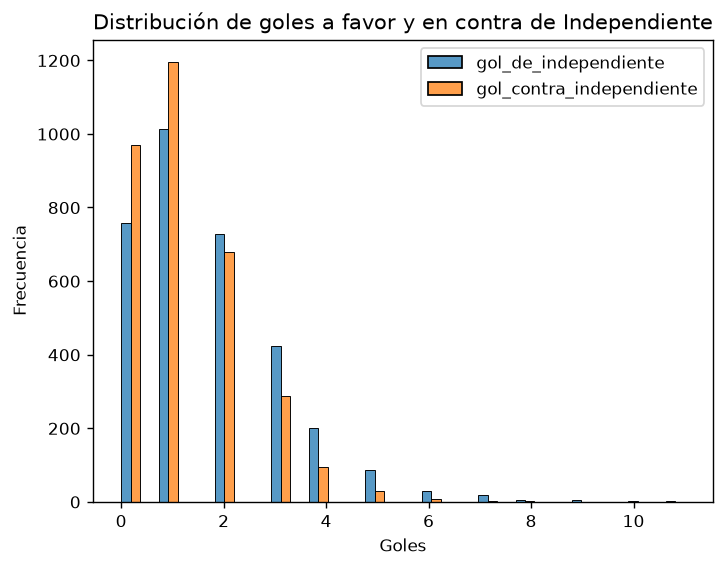

In [98]:
sns.histplot(data=df_independiente[['gol_de_independiente', 'gol_contra_independiente']],multiple='dodge',bins=30)
plt.title("Distribución de goles a favor y en contra de Independiente")
plt.xlabel("Goles")
plt.ylabel("Frecuencia")
plt.show()

<Axes: title={'center': 'Resultados del CAI'}>

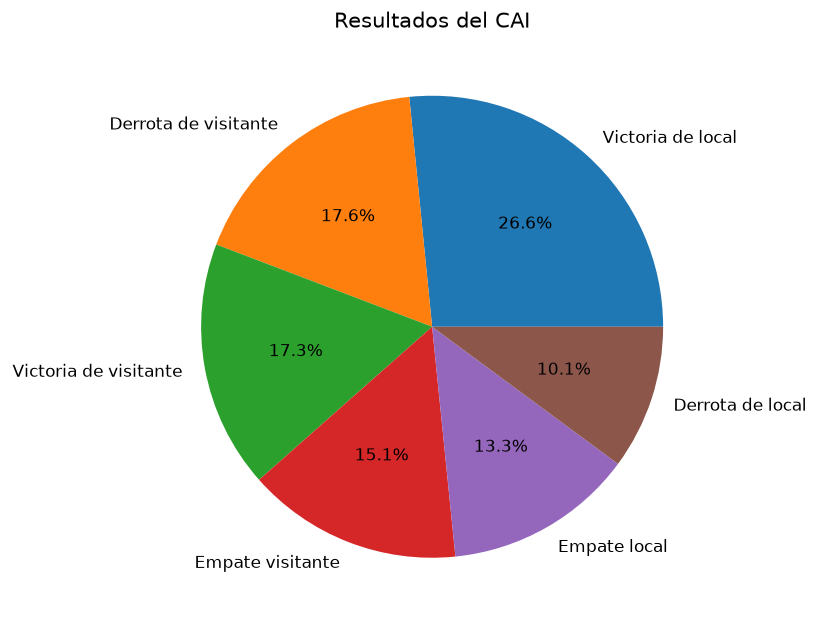

In [63]:
df_independiente['victoria_independiente'].value_counts().plot(kind='pie', title='Resultados del CAI',autopct='%1.1f%%', figsize=(6, 6))

In [121]:
goles_año=df_independiente.groupby(['anio', 'condicion_independiente'])[['gol_de_independiente', 'gol_contra_independiente']].mean().reset_index()
goles_graph = goles_año.melt(
    id_vars=['anio', 'condicion_independiente'], 
    value_vars=['gol_de_independiente', 'gol_contra_independiente'],
    var_name='tipo_de_gol',
    value_name='cantidad_goles'
)

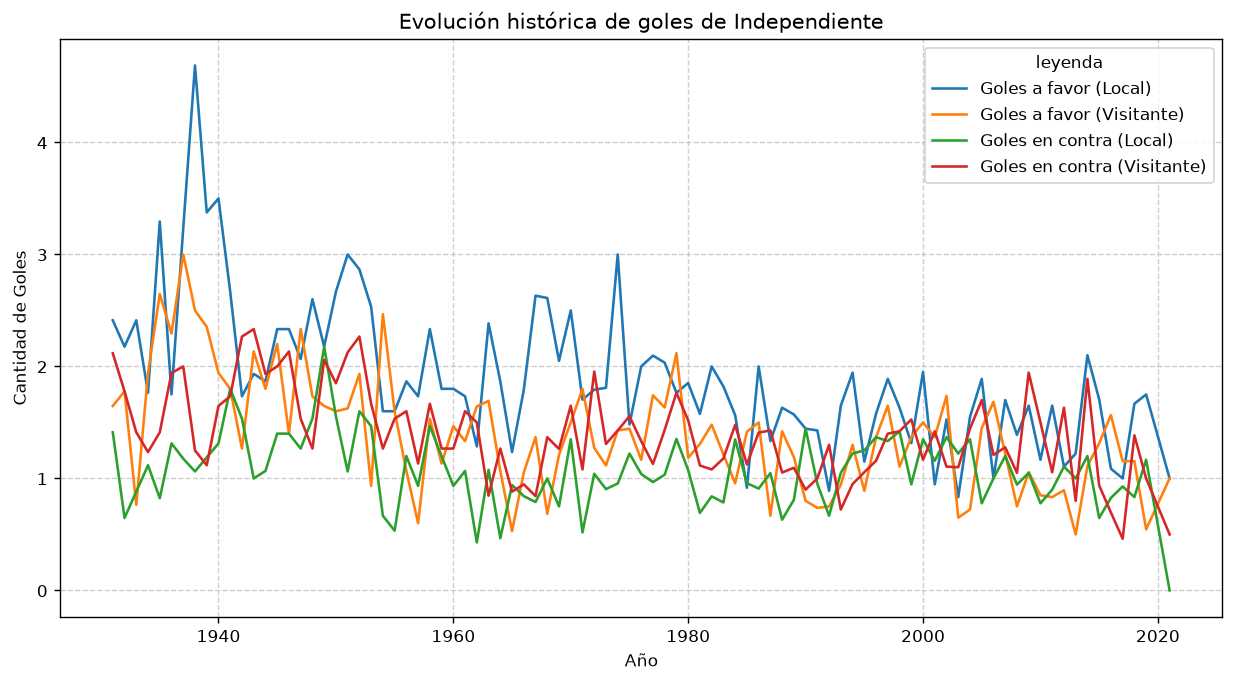

In [122]:
goles_graph['tipo_de_gol'] = goles_graph['tipo_de_gol'].replace({
    'gol_de_independiente': 'Goles a favor',
    'gol_contra_independiente': 'Goles en contra'
})

goles_graph['leyenda'] = goles_graph['tipo_de_gol'] + ' (' + goles_graph['condicion_independiente'] + ')'

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=goles_graph, 
    x='anio', 
    y='cantidad_goles', 
    hue='leyenda')

plt.title('Evolución histórica de goles de Independiente')
plt.xlabel('Año')
plt.ylabel('Cantidad de Goles')
plt.grid(True, linestyle='--', alpha=0.6) # Una grilla suave de fondo

plt.show()